<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockGPT2Tab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rows with known target: 332
Class counts: {0: 191, 1: 141}
Train 215 {0: 123, 1: 92}
Validation 50 {0: 29, 1: 21}
Test 67 {0: 39, 1: 28}
Encoded input dimension: 19
Class weights: [0.87398374 1.16847826]


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Epoch 50/500 | train=0.6998 | val=0.6929 | ROC-AUC=0.4729 | PR-AUC=0.4132 | balanced accuracy=0.5378
Epoch 100/500 | train=0.5215 | val=0.6811 | ROC-AUC=0.5870 | PR-AUC=0.5787 | balanced accuracy=0.6199
Epoch 150/500 | train=0.4762 | val=0.9959 | ROC-AUC=0.5296 | PR-AUC=0.5786 | balanced accuracy=0.6519
Epoch 200/500 | train=0.4431 | val=1.1300 | ROC-AUC=0.6034 | PR-AUC=0.6371 | balanced accuracy=0.6716
Epoch 250/500 | train=0.4196 | val=0.9800 | ROC-AUC=0.5772 | PR-AUC=0.6333 | balanced accuracy=0.6519
Epoch 300/500 | train=0.4413 | val=0.9119 | ROC-AUC=0.5378 | PR-AUC=0.5638 | balanced accuracy=0.6149
Epoch 350/500 | train=0.4161 | val=1.1908 | ROC-AUC=0.5263 | PR-AUC=0.5725 | balanced accuracy=0.6215
Epoch 400/500 | train=0.3550 | val=1.4586 | ROC-AUC=0.5230 | PR-AUC=0.5675 | balanced accuracy=0.6281
Epoch 450/500 | train=0.3367 | val=1.7696 | ROC-AUC=0.5328 | PR-AUC=0.5819 | balanced accuracy=0.6281
Epoch 500/500 | train=0.3314 | val=2.1484 | ROC-AUC=0.5181 | PR-AUC=0.5020 | balanc

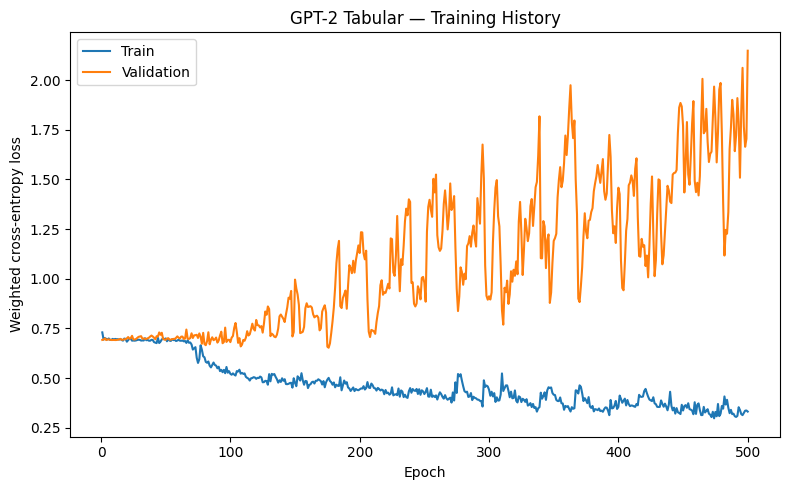


CHECKPOINT: best_val_loss | Epoch: 176
Checkpoint                      best_val_loss
Epoch                                     176
Threshold                            0.561564
Validation_Loss                      0.652912
Validation_ROC_AUC                   0.600164
Validation_PR_AUC                    0.616498
Validation_Balanced_Accuracy         0.699507
Balanced_Accuracy                    0.731685
F1                                   0.679245
ROC_AUC                              0.815934
PR_AUC                               0.814919
Confusion matrix:
 [[32  7]
 [10 18]]
              precision    recall  f1-score   support

HPV Negative     0.7619    0.8205    0.7901        39
HPV Positive     0.7200    0.6429    0.6792        28

    accuracy                         0.7463        67
   macro avg     0.7410    0.7317    0.7347        67
weighted avg     0.7444    0.7463    0.7438        67


CHECKPOINT: best_val_roc_auc | Epoch: 208
Checkpoint                      best_val_roc_a

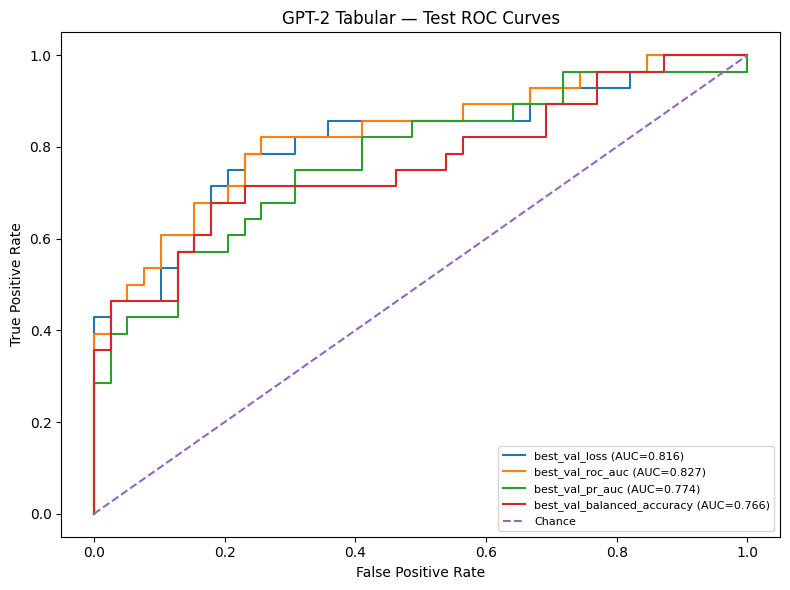

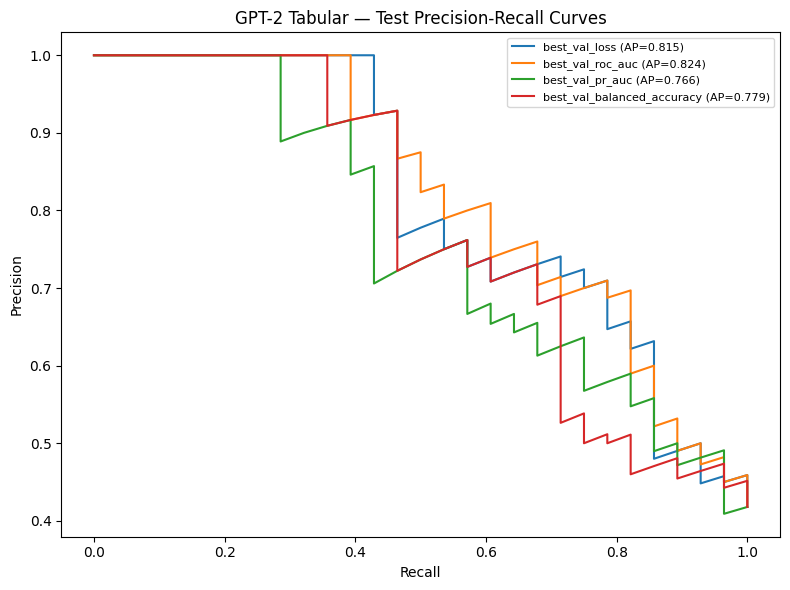

All results saved to: /content/drive/MyDrive/GPT2_Tabular_Hancock_results
Files: ['checkpoints', 'metrics_all_checkpoints.csv', 'run_summary.json', 'tabular_preprocessor.joblib', 'test_pr_curves.png', 'test_predictions_all_checkpoints.csv', 'test_roc_curves.png', 'training_history.csv', 'training_history.png']


In [2]:

# HANCOCK HPV — GPT-2 TABULAR CLASSIFIER
# Matched protocol: clinical narrative reference
# 65/15/20 stratified split | Seed 42 | Batch 64 | 500 epochs
# No SMOTE | Four validation-selected checkpoints

import os
import json
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib

from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive
from transformers import GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
MODEL_NAME = "openai-community/gpt2"


# ============================================================
# 1. REPRODUCIBILITY AND DEVICE
# ============================================================

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

drive.mount("/content/drive")

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "GPT2_Tabular_Hancock_results")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


# ============================================================
# 2. LOAD AND PREPARE DATA
# ============================================================

def load_json_table(path):
    with open(path, encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if isinstance(obj.get(key), list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table: {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)
pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical.columns:
    raise KeyError("clinical_data.json must contain patient_id.")

if "patient_id" not in pathology.columns:
    raise KeyError("pathological_data.json must contain patient_id.")

df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

target_col = next(
    (
        c for c in [
            "hpv_association_p16",
            "hpv_association_p16_path"
        ]
        if c in df.columns
    ),
    None
)

if target_col is None:
    raise KeyError("Could not find hpv_association_p16 target.")

feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}

rename_map = {}

for feature, candidates in feature_candidates.items():
    found = next(
        (c for c in candidates if c in df.columns),
        None
    )

    if found is None:
        raise KeyError(
            f"Missing predictor {feature}; checked {candidates}"
        )

    if found != feature:
        rename_map[found] = feature

df = df.rename(columns=rename_map)
features = list(feature_candidates)


def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"negative", "neg", "0", "false", "no"}:
        return 0

    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1

    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[
    ["patient_id"] + features + ["HPV_Label"]
].copy()

print("Rows with known target:", len(df))
print(
    "Class counts:",
    df["HPV_Label"].value_counts().sort_index().to_dict()
)


# ============================================================
# 3. STRATIFIED 65/15/20 TRAIN/VALIDATION/TEST SPLIT
# ============================================================

train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train, val, test = [
    part.reset_index(drop=True)
    for part in (train, val, test)
]

for name, part in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(
        name,
        len(part),
        part["HPV_Label"].value_counts().sort_index().to_dict()
    )

X_train_df, X_val_df, X_test_df = [
    part[features].copy()
    for part in (train, val, test)
]

y_train, y_val, y_test = [
    part["HPV_Label"].to_numpy(dtype=np.int64)
    for part in (train, val, test)
]


# ============================================================
# 4. IMPUTATION AND ONE-HOT ENCODING
# ============================================================

numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [
    c for c in features if c not in numeric_features
]

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = pd.to_numeric(
        frame["age_at_initial_diagnosis"],
        errors="coerce"
    )

age_median = X_train_df[
    "age_at_initial_diagnosis"
].median()

if pd.isna(age_median):
    age_median = 0.0

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = (
        frame["age_at_initial_diagnosis"].fillna(age_median)
    )

for col in categorical_features:
    modes = X_train_df[col].dropna().astype(str).mode()
    fill_value = modes.iloc[0] if not modes.empty else "Unknown"

    for frame in (X_train_df, X_val_df, X_test_df):
        frame[col] = frame[col].fillna(fill_value)
        frame[col] = frame[col].astype(str).replace({
            "": "Unknown",
            "nan": "Unknown",
            "None": "Unknown"
        })

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", encoder, categorical_features)
])

X_train = preprocessor.fit_transform(
    X_train_df
).astype(np.float32)

X_val = preprocessor.transform(
    X_val_df
).astype(np.float32)

X_test = preprocessor.transform(
    X_test_df
).astype(np.float32)

print("Encoded input dimension:", X_train.shape[1])


# ============================================================
# 5. CLASS WEIGHTS — NO SMOTE
# ============================================================

counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both classes must be present in training data."
    )

weights = len(y_train) / (2.0 * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Class weights:", weights)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

X_val_t = torch.tensor(
    X_val, dtype=torch.float32, device=device
)
y_val_t = torch.tensor(
    y_val, dtype=torch.long, device=device
)
X_test_t = torch.tensor(
    X_test, dtype=torch.float32, device=device
)


# ============================================================
# 6. TABULAR GPT-2 ARCHITECTURE — PRESERVED
# ============================================================

class GPT2TabularClassifier(nn.Module):
    def __init__(self, n_features, dropout=0.1):
        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)
        hidden = self.gpt2.config.hidden_size

        self.feature_projection = nn.Linear(1, hidden)

        self.feature_embedding = nn.Parameter(
            torch.zeros(1, n_features, hidden)
        )
        nn.init.normal_(
            self.feature_embedding,
            mean=0.0,
            std=0.02
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden),
            nn.Dropout(dropout),
            nn.Linear(hidden, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        tokens = self.feature_projection(x.unsqueeze(-1))
        tokens = tokens + self.feature_embedding

        hidden = self.gpt2(
            inputs_embeds=tokens
        ).last_hidden_state

        return self.classifier(hidden.mean(dim=1))


model = GPT2TabularClassifier(
    X_train.shape[1],
    DROPOUT
).to(device)


# Match clinical narrative weighted-loss calculation
def weighted_classification_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits,
        labels,
        reduction="none"
    )
    return (losses * class_weights[labels]).mean()


def evaluate_loss():
    model.eval()

    with torch.no_grad():
        return weighted_classification_loss(
            model(X_val_t),
            y_val_t
        ).item()


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


def predict_probabilities(X_tensor):
    model.eval()

    with torch.no_grad():
        return torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1].cpu().numpy()


# ============================================================
# 7. VALIDATION THRESHOLD AND METRICS
# ============================================================

def select_threshold(y_true, probabilities):
    thresholds = np.unique(
        np.concatenate(([0.0], probabilities, [1.0]))
    )

    results = [
        (
            float(t),
            balanced_accuracy_score(
                y_true,
                (probabilities >= t).astype(int)
            )
        )
        for t in thresholds
    ]

    # Maximise balanced accuracy; ties closest to 0.5
    return max(
        results,
        key=lambda x: (x[1], -abs(x[0] - 0.5))
    )


def validation_metrics():
    p = predict_probabilities(X_val_t)
    threshold, bal_acc = select_threshold(y_val, p)

    roc_auc = (
        roc_auc_score(y_val, p)
        if len(np.unique(y_val)) == 2
        else np.nan
    )

    return {
        "threshold": float(threshold),
        "balanced_accuracy": float(bal_acc),
        "roc_auc": float(roc_auc),
        "pr_auc": float(average_precision_score(y_val, p))
    }


checkpoint_specs = {
    "best_val_loss": (
        "gpt2_best_val_loss.pt", "min"
    ),
    "best_val_roc_auc": (
        "gpt2_best_val_roc_auc.pt", "max"
    ),
    "best_val_pr_auc": (
        "gpt2_best_val_pr_auc.pt", "max"
    ),
    "best_val_balanced_accuracy": (
        "gpt2_best_val_balanced_accuracy.pt", "max"
    )
}

best_values = {
    "best_val_loss": float("inf"),
    "best_val_roc_auc": -float("inf"),
    "best_val_pr_auc": -float("inf"),
    "best_val_balanced_accuracy": -float("inf")
}

best_epochs = {}
history = []


# ============================================================
# 8. TRAIN — 500 EPOCHS
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    loss_sum = 0.0
    n_seen = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        loss = weighted_classification_loss(
            model(xb), yb
        )

        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(yb)
        n_seen += len(yb)

    train_loss = loss_sum / max(n_seen, 1)
    val_loss = evaluate_loss()
    vm = validation_metrics()

    history.append({
        "epoch": int(epoch),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_roc_auc": float(vm["roc_auc"]),
        "val_pr_auc": float(vm["pr_auc"]),
        "val_balanced_accuracy": float(vm["balanced_accuracy"]),
        "val_threshold": float(vm["threshold"])
    })

    scores = {
        "best_val_loss": val_loss,
        "best_val_roc_auc": vm["roc_auc"],
        "best_val_pr_auc": vm["pr_auc"],
        "best_val_balanced_accuracy": vm["balanced_accuracy"]
    }

    for key, score in scores.items():
        direction = checkpoint_specs[key][1]

        improved = (
            score < best_values[key]
            if direction == "min"
            else score > best_values[key]
        )

        if not np.isfinite(score) or not improved:
            continue

        best_values[key] = float(score)
        best_epochs[key] = int(epoch)

        # Store only standard Python scalar metadata.
        checkpoint_data = {
            "epoch": int(epoch),
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "validation_loss": float(val_loss),
            "validation_roc_auc": float(vm["roc_auc"]),
            "validation_pr_auc": float(vm["pr_auc"]),
            "validation_balanced_accuracy": float(
                vm["balanced_accuracy"]
            ),
            "validation_threshold": float(vm["threshold"])
        }

        torch.save(
            checkpoint_data,
            os.path.join(
                CHECKPOINT_DIR,
                checkpoint_specs[key][0]
            )
        )

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{MAX_EPOCHS} | "
            f"train={train_loss:.4f} | "
            f"val={val_loss:.4f} | "
            f"ROC-AUC={vm['roc_auc']:.4f} | "
            f"PR-AUC={vm['pr_auc']:.4f} | "
            f"balanced accuracy={vm['balanced_accuracy']:.4f}"
        )

if len(history) != MAX_EPOCHS:
    raise RuntimeError(
        f"Expected {MAX_EPOCHS} epochs; ran {len(history)}."
    )

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(OUT_DIR, "training_history.csv"),
    index=False
)

print("Best checkpoint epochs:", best_epochs)

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy loss")
plt.title("GPT-2 Tabular — Training History")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "training_history.png"),
    dpi=150
)
plt.show()


# ============================================================
# 9. TEST EACH SELECTED CHECKPOINT
# ============================================================

all_metrics = []
all_predictions = []
test_probabilities = {}

for name, (filename, _) in checkpoint_specs.items():
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR, filename
    )

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}. "
            "Run the training section first, or check Drive."
        )

    # FIX FOR PYTORCH 2.6+:
    # Use weights_only=False only for trusted checkpoints
    # generated by this notebook.
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    val_prob = predict_probabilities(X_val_t)
    test_prob = predict_probabilities(X_test_t)
    test_probabilities[name] = test_prob

    # Select threshold from validation data only.
    threshold, val_bal_acc = select_threshold(
        y_val, val_prob
    )

    test_pred = (test_prob >= threshold).astype(int)

    test_roc_auc = (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    )

    test_pr_auc = average_precision_score(
        y_test, test_prob
    )

    metrics = {
        "Checkpoint": name,
        "Epoch": int(checkpoint["epoch"]),
        "Threshold": float(threshold),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_bal_acc),
        "Balanced_Accuracy": float(
            balanced_accuracy_score(y_test, test_pred)
        ),
        "F1": float(
            f1_score(y_test, test_pred, zero_division=0)
        ),
        "ROC_AUC": float(test_roc_auc),
        "PR_AUC": float(test_pr_auc)
    }

    all_metrics.append(metrics)

    all_predictions.append(pd.DataFrame({
        "patient_id": test["patient_id"].to_numpy(),
        "y_true": y_test,
        "probability_positive": test_prob,
        "prediction": test_pred,
        "checkpoint": name,
        "epoch": int(checkpoint["epoch"]),
        "threshold": float(threshold)
    }))

    print("\n", "=" * 55)
    print("CHECKPOINT:", name, "| Epoch:", checkpoint["epoch"])
    print(pd.Series(metrics).to_string())

    print(
        "Confusion matrix:\n",
        confusion_matrix(y_test, test_pred, labels=[0, 1])
    )

    print(classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4,
        zero_division=0
    ))

pd.DataFrame(all_metrics).to_csv(
    os.path.join(OUT_DIR, "metrics_all_checkpoints.csv"),
    index=False
)

pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    os.path.join(
        OUT_DIR,
        "test_predictions_all_checkpoints.csv"
    ),
    index=False
)


# ============================================================
# 10. TEST ROC CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    if len(np.unique(y_test)) < 2:
        continue

    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GPT-2 Tabular — Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_roc_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 11. TEST PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, p)
    ap = average_precision_score(y_test, p)

    plt.plot(
        recall, precision,
        label=f"{name} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("GPT-2 Tabular — Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_pr_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 12. SAVE PREPROCESSOR AND RUN SUMMARY
# ============================================================

joblib.dump(
    preprocessor,
    os.path.join(OUT_DIR, "tabular_preprocessor.joblib")
)

summary = {
    "seed": SEED,
    "model_name": MODEL_NAME,
    "epochs": MAX_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "original_predictors": features,
    "encoded_feature_count": int(X_train.shape[1]),
    "train_rows": int(len(train)),
    "validation_rows": int(len(val)),
    "test_rows": int(len(test)),
    "smote": False,
    "gradient_clipping": False,
    "gpt2_fine_tuned": True,
    "class_weights": [
        float(w) for w in class_weights.detach().cpu().tolist()
    ],
    "checkpoint_selection": (
        "Best validation loss, ROC-AUC, PR-AUC "
        "and balanced accuracy"
    ),
    "threshold_selection": (
        "Maximise validation balanced accuracy over unique "
        "scores plus 0 and 1; ties closest to 0.5"
    ),
    "loss": (
        "Mean per-example cross-entropy multiplied "
        "by target-class weight"
    ),
    "best_epochs": {
        k: int(v) for k, v in best_epochs.items()
    }
}

with open(
    os.path.join(OUT_DIR, "run_summary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print("All results saved to:", OUT_DIR)
print("Files:", sorted(os.listdir(OUT_DIR)))
